# 01 — Exploración (Data Understanding)

**Objetivo:** entender los datos demográficos de Naciones Unidas antes de tocarlos: qué significa cada columna, qué representa cada fila, cuántos nulos hay, qué rangos y distribuciones tienen y cómo se enlazan con PISA.

Datasets explorados (World Population Prospects 2024):

- `WPP2024_Demographic_Indicators_Medium_csv.gz`: 54 indicadores demográficos por país/región y año, variante media.
- `WPP2024_Supplement_Births_and_LE60.csv`: nacimientos por sexo y esperanza de vida a los 60 años.
- `WPP2024_Demographic_Indicators_OtherVariants_csv.gz`: los mismos indicadores con otros escenarios de proyección e intervalos de predicción (2024-2101).
- `WPP2024_Demographic_Indicators_notes.csv`: diccionario de los indicadores (nombre, tema y unidad).

- Gráficos rápidos, solo para mí: estoy buscando patrones, no hace falta que sean bonitos.
- Aquí **no se modifica ni se guarda nada**: solo se lee de `data/raw/` (y `data/processed/pisa_unificado.csv` para comprobar el enlace).
- Lo que encuentre lo apunto al final: será la lista de tareas de `02_limpieza`.

### Criterios de trabajo (técnicos y éticos, ASA)

Reglas que sigo en todo el notebook y que se mantienen en los siguientes:

1. **Sin doble conteo:** `Location` mezcla países con agregados. Para comparar o sumar países se filtra siempre `LocTypeName == "Country/Area"` (equivale a `ISO3_code.notna()`, se comprueba en la sección 3).
2. **Unidades explícitas:** los conteos (población, nacimientos, muertes, migrantes) están en **miles**; las tasas, por 1.000 habitantes o nacidos vivos; `TFR`, en hijos por mujer. Para cifras absolutas, multiplicar por 1.000.
3. **Hechos vs. supuestos:** 1950-2023 son **estimaciones** (censos, registros, encuestas y modelos); 2024-2101 son **proyecciones** que dependen de supuestos. Cada resultado indica de qué periodo sale y los gráficos marcan la frontera.
4. **La variante media no es una certeza:** cualquier resultado prospectivo se contrasta con los intervalos de predicción y los escenarios de `OtherVariants`.
5. **Sin selección a conveniencia:** los años de corte se fijan antes de mirar los resultados (ciclos de PISA, frontera 2023) y se documentan; no se eligen variantes ni años para respaldar una narrativa.
6. **Calidad desigual de los datos:** en países con registros civiles incompletos o en conflicto, las estimaciones históricas se apoyan en censos antiguos o modelos indirectos y tienen más error. WPP no publica ese error por país en estos archivos: se tiene en cuenta al interpretar.
7. **Contexto y no estigmatización:** fecundidad, mortalidad infantil y migración se interpretan junto a sus determinantes socioeconómicos y geopolíticos, sin determinismo demográfico ni lecturas que estigmaticen regiones o flujos migratorios.
8. **Reproducibilidad:** todo se carga directamente de los `.csv`/`.csv.gz` originales de `data/raw/`; no hay pasos manuales ni procesos aleatorios.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # permite importar src/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import DATA_RAW, cargar_raw, cargar_processed, resumen
from src.estilo import aplicar_estilo, CMAP_DIVERGENTE, CMAP_SECUENCIAL, DESTACADO, GRIS

aplicar_estilo()
pd.set_option("display.max_columns", None)

ULTIMO_ESTIMADO = 2023  # último año estimado de WPP2024; desde 2024 todo es proyección

## 1. Carga de datos

**Fuente:** Naciones Unidas, División de Población, [World Population Prospects 2024](https://population.un.org/wpp/). Descargado el 2026-10-14.

- Estimaciones de 1950 a 2023; **proyecciones** (variante media) de 2024 a 2101.
- Cifras absolutas (población, nacimientos, muertes, migrantes) en **miles**.
- Los `.csv.gz` se leen directamente comprimidos (`compression="gzip"`) y con `encoding="utf-8-sig"`, que ignora el BOM si el archivo lo trae.

In [2]:
# Archivos disponibles en data/raw/
[p.name for p in DATA_RAW.iterdir() if p.name != ".gitkeep"]

['PISA2022_cap2_desempeno.xlsx',
 'PISA2022_cap3_niveles.xlsx',
 'PISA2022_cap4_equidad_genero.xlsx',
 'PISA2022_cap7_migracion.xlsx',
 'PISA2025_cap2a_desempeno_niveles.xlsx',
 'PISA2025_cap2c_genero.xlsx',
 'PISA2025_cap2d_migracion.xlsx',
 'PISA_BancoMundial_2000_2018.csv',
 'WPP2024_Demographic_Indicators_Medium_csv.gz',
 'WPP2024_Demographic_Indicators_notes.csv',
 'WPP2024_Demographic_Indicators_OtherVariants_csv.gz',
 'WPP2024_Supplement_Births_and_LE60.csv']

In [3]:
dem = cargar_raw(
    "WPP2024_Demographic_Indicators_Medium_csv.gz",
    compression="gzip",
    encoding="utf-8-sig",
    low_memory=False,
)
print("Medium:", dem.shape)
dem.head()

Medium: (84360, 67)


,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1950,68501.280,69213.424,35880.164,33333.260,12.5144,107.6407,19.3872,1223.088,17.671,1424.288,2.058,33.6806,2933.594,429.475,42.385,5.9875,1.6659,29.297,105.8,1710.506,896.754,813.752,24.714,38.6085,38.1082,39.1261,44.2999,43.9332,44.7392,10.9511,10.4530,11.4857,4.8798,4.6064,5.1054,600.102,207.0834,2523.217,930.552,326.3591,483.8022,480.5664,488.1621,643.6878,654.5798,631.8067,297.6529,298.4483,297.2079,443.3215,457.3384,427.3167,201.196,2.907
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1951,69925.568,70682.760,36615.258,34067.503,12.7800,107.4785,19.4969,1319.315,18.665,1514.384,2.143,32.3447,3012.920,435.748,42.626,5.9815,1.7067,29.309,105.8,1693.605,888.959,804.646,23.961,39.6435,39.1333,40.1776,44.5777,44.1812,45.0496,10.9994,10.4858,11.5551,4.9081,4.6030,5.1636,600.824,200.9781,2603.729,910.110,311.6260,469.2924,465.8440,473.8063,631.3550,642.5944,619.1788,292.4375,293.1236,292.0887,436.9979,451.4368,420.7398,195.070,2.760
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1952,71439.952,72238.716,37394.815,34843.901,13.0614,107.3210,19.5624,1414.859,19.586,1597.527,2.212,31.3358,3099.971,445.389,42.913,5.9847,1.7433,29.330,105.8,1685.112,884.170,800.942,23.327,40.5673,40.0791,41.0807,44.8853,44.4688,45.3766,11.0501,10.5324,11.6132,4.9267,4.6133,5.1904,602.648,196.0193,2689.275,898.759,299.5189,456.3412,452.3689,461.3362,619.6089,630.8166,607.6061,286.6916,287.3395,286.3341,429.8298,444.5151,413.5565,182.671,2.529
3,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1953,73037.479,73876.364,38216.384,35659.980,13.3575,107.1688,19.5850,1513.580,20.488,1677.771,2.271,30.5217,3193.546,458.493,43.228,5.9954,1.7815,29.357,105.9,1679.966,882.165,797.801,22.740,41.4405,40.9378,41.9706,45.1676,44.7348,45.6739,11.0968,10.5786,11.6627,4.9460,4.6269,5.2154,603.859,190.7597,2781.713,889.725,288.1312,444.1330,440.1555,449.0918,608.4672,619.9937,596.2667,281.4671,282.0251,281.1446,423.2008,438.1189,406.9265,164.189,2.222
4,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1954,74715.250,75600.454,39082.204,36518.249,13.6692,107.0210,19.5886,1607.345,21.261,1770.407,2.342,29.5964,3288.272,466.430,43.495,6.0042,1.8136,29.379,105.9,1680.927,882.632,798.295,22.234,42.2044,41.7062,42.7313,45.4180,44.9573,45.9532,11.1380,10.6171,11.7092,4.9629,4.6392,5.2372,605.992,185.8880,2874.963,885.494,278.3146,433.4326,429.2479,438.5606,598.6442,610.3878,586.3428,276.8312,277.5799,276.2557,417.3453,432.7454,400.7629,163.064,2.157


In [4]:
sup = cargar_raw("WPP2024_Supplement_Births_and_LE60.csv", encoding="utf-8-sig")
print("Supplement:", sup.shape)
sup.head()

Supplement: (35636, 9)


,LocID,ISO3_code,Location,Time,BirthsMale,BirthsFemale,LE60,LE60Male,LE60Female
0,4,AFG,Afghanistan,1950,196.623,187.363,10.700,10.386,11.132
1,4,AFG,Afghanistan,1951,200.216,190.786,10.777,10.453,11.221
2,4,AFG,Afghanistan,1952,203.609,194.054,10.852,10.517,11.309
3,4,AFG,Afghanistan,1953,207.190,197.476,10.929,10.582,11.398
4,4,AFG,Afghanistan,1954,210.168,200.260,10.961,10.608,11.434


In [5]:
dic = cargar_raw("WPP2024_Demographic_Indicators_notes.csv", encoding="utf-8-sig")
print("Diccionario:", dic.shape)
dic

Diccionario: (59, 5)


,IndicatorNo,Topic,Indicator,IndicatorName,Unit
0,1,Population,TPopulation1Jan,"Total Population, as of 1 January",thousands
1,2,Population,TPopulation1July,"Total Population, as of 1 July",thousands
2,3,Population,TPopulationMale1July,"Male Population, as of 1 July",thousands
3,4,Population,TPopulationFemale1July,"Female Population, as of 1 July",thousands
4,5,Population,PopDensity,"Population Density, as of 1 July",persons per square km
5,6,Population,PopSexRatio,"Population Sex Ratio, as of 1 July",males per 100 females
6,7,Population,MedianAgePop,"Median Age, as of 1 July",years
7,8,Population,NatChange,"Natural Change, Births minus Deaths",thousands
8,9,Population,NatChangeRT,Rate of Natural Change,"per 1,000 population"
9,10,Population,PopChange,Population Change,thousands


## 2. Diccionario de columnas

Los 54 indicadores del Medium están descritos en `dic` (arriba). Las columnas que no son indicadores:

| Columna | Significado | Tipo esperado | Notas |
|---|---|---|---|
| `SortOrder` | Orden de presentación de la ONU | int | Solo en agregados; vacío en países |
| `LocID` | Código numérico de ubicación (M49) | int | Clave estable, también en el Supplement |
| `Notes` | Código de nota al pie | texto | El texto de la nota no viene en los archivos |
| `ISO3_code` / `ISO2_code` | Código ISO del país | texto | Vacío en agregados; **clave para unir con PISA** |
| `SDMX_code` | Código SDMX | int | Mayormente vacío |
| `LocTypeID` / `LocTypeName` | Tipo de ubicación (país, región, grupo de ingreso...) | categórica | Hay que filtrar `Country/Area` |
| `ParentID` | `LocID` de la región que lo contiene | int | Solo en agregados |
| `Location` | Nombre de la ubicación (en inglés) | texto | |
| `VarID` / `Variant` | Variante de proyección | categórica | Siempre `Medium` en este archivo |
| `Time` | Año | int | 1950–2101 |

**Supplement** (ya en el Medium: `LocID`, `ISO3_code`, `Location`, `Time`):

| Columna | Significado | Unidad | Notas |
|---|---|---|---|
| `BirthsMale` / `BirthsFemale` | Nacimientos de niños / niñas | miles | Su suma debería ser `Births` |
| `LE60` | Esperanza de vida a los 60 años, ambos sexos | años | Años que le quedan por vivir a quien llega a 60 |
| `LE60Male` / `LE60Female` | Ídem por sexo | años | |

In [6]:
# ¿Todas las columnas de indicadores del Medium están en el diccionario?
ids = [
    "SortOrder",
    "LocID",
    "Notes",
    "ISO3_code",
    "ISO2_code",
    "SDMX_code",
    "LocTypeID",
    "LocTypeName",
    "ParentID",
    "Location",
    "VarID",
    "Variant",
    "Time",
]
indicadores = [c for c in dem.columns if c not in ids]
print("Indicadores en el Medium:", len(indicadores))
print("Sin descripción:", set(indicadores) - set(dic["Indicator"]))
print("Descritos pero ausentes:", set(dic["Indicator"]) - set(indicadores))

Indicadores en el Medium: 54
Sin descripción: set()
Descritos pero ausentes: {'LE60', 'LE60Female', 'LE60Male', 'BirthsFemale', 'BirthsMale'}


In [7]:
dic.groupby("Topic")["Indicator"].apply(list)

Topic
Fertility     [Births, BirthsMale, BirthsFemale, Births1519,...
Migration                                 [NetMigrations, CNMR]
Mortality     [Deaths, DeathsMale, DeathsFemale, CDR, LEx, L...
Population    [TPopulation1Jan, TPopulation1July, TPopulatio...
Name: Indicator, dtype: object

In [8]:
# Unidades: qué indicadores son conteos (en miles) y cuáles son tasas o medidas relativas
dic.groupby("Unit")["Indicator"].apply(list).sort_values(key=lambda s: -s.str.len())

Unit
years                                                    [MedianAgePop, DoublingTime, MAC, LEx, LExMale...
thousands                                                [TPopulation1Jan, TPopulation1July, TPopulatio...
per 1,000 population                                                                   [NatChangeRT, CNMR]
births per 1,000 population                                                                          [CBR]
deaths under age 40 per 1,000 male live births                                                 [Q0040Male]
deaths per 1,000 population                                                                          [CDR]
deaths under age 40 per 1,000 female live births                                             [Q0040Female]
deaths under age 40 per 1,000 live births                                                          [Q0040]
deaths under age 50 per 1,000 males alive at age 15                                            [Q1550Male]
deaths under age 60 per 1,000 al

In [9]:
dem.info()

<class 'pandas.DataFrame'>
RangeIndex: 84360 entries, 0 to 84359
Data columns (total 67 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   SortOrder               48792 non-null  float64
 1   LocID                   84360 non-null  int64  
 2   Notes                   11856 non-null  str    
 3   ISO3_code               36024 non-null  str    
 4   ISO2_code               35872 non-null  str    
 5   SDMX_code               43320 non-null  float64
 6   LocTypeID               48792 non-null  float64
 7   LocTypeName             48792 non-null  str    
 8   ParentID                48792 non-null  float64
 9   Location                84360 non-null  str    
 10  VarID                   84360 non-null  int64  
 11  Variant                 84360 non-null  str    
 12  Time                    84360 non-null  int64  
 13  TPopulation1Jan         84360 non-null  float64
 14  TPopulation1July        83805 non-null  float64
 

In [10]:
sup.info()

<class 'pandas.DataFrame'>
RangeIndex: 35636 entries, 0 to 35635
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   LocID         35636 non-null  int64  
 1   ISO3_code     35636 non-null  str    
 2   Location      35636 non-null  str    
 3   Time          35636 non-null  int64  
 4   BirthsMale    35636 non-null  float64
 5   BirthsFemale  35636 non-null  float64
 6   LE60          35636 non-null  float64
 7   LE60Male      35636 non-null  float64
 8   LE60Female    35636 non-null  float64
dtypes: float64(5), int64(2), str(2)
memory usage: 2.9 MB


## 3. Estructura: qué representa cada fila

En el Medium una fila es **una ubicación en un año**, pero las ubicaciones mezclan países con agregados (Mundo, continentes, grupos de ingreso...). Si se suman o promedian sin filtrar, se cuenta todo varias veces.

In [11]:
dem["LocTypeName"].value_counts()

LocTypeName
Country/Area         36024
Ad Hoc groups         3496
Subregion             3192
SDG region            1368
Income group          1368
Development group     1064
Special other         1064
Geographic region     1064
World                  152
Name: count, dtype: int64

In [12]:
# Variante y rango de años
print(dem["Variant"].value_counts())
print("Años:", dem["Time"].min(), "-", dem["Time"].max())
print("Años por ubicación:", dem.groupby("LocID").size().unique())

Variant
Medium    84360
Name: count, dtype: int64
Años: 1950 - 2101
Años por ubicación: [152]


In [13]:
# Agregados disponibles (útiles para comparar contra el promedio mundial o regional)
dem.loc[dem["LocTypeName"] != "Country/Area"].groupby("LocTypeName")[
    "Location"
].unique()

LocTypeName
Ad Hoc groups        [Group A – already peaked (before 2024), Group...
Development group    [More developed regions, Less developed region...
Geographic region    [Africa, Asia, Europe, Americas, Latin America...
Income group         [High-and-upper-middle-income countries, Low-a...
SDG region           [Sub-Saharan Africa, Northern Africa and Weste...
Special other        [LLDC: Africa, LLDC: Asia, LLDC: Europe, LLDC:...
Subregion            [Eastern Africa, Middle Africa, Northern Afric...
World                                                          [World]
Name: Location, dtype: object

In [14]:
# ¿Filtrar por LocTypeName o por ISO3_code da lo mismo?
pd.crosstab(dem["LocTypeName"], dem["ISO3_code"].notna().rename("tiene ISO3"))

tiene ISO3,False,True
LocTypeName,,
Ad Hoc groups,3496,0
Country/Area,0,36024
Development group,1064,0
Geographic region,1064,0
Income group,1368,0
SDG region,1368,0
Special other,1064,0
Subregion,3192,0
World,152,0


In [15]:
# Qué pasa si se suma sin filtrar: población de 2023 (en miles)
d = dem.loc[dem["Time"] == ULTIMO_ESTIMADO]
print(
    f"Suma de todas las filas:   {d['TPopulation1July'].sum() * 1000:>20,.0f} personas"
)
print(
    f"Suma solo de países:       {d.loc[d['ISO3_code'].notna(), 'TPopulation1July'].sum() * 1000:>20,.0f} personas"
)
print(
    f"Fila 'World':              {d.loc[d['LocTypeName'] == 'World', 'TPopulation1July'].iloc[0] * 1000:>20,.0f} personas"
)

Suma de todas las filas:        362,865,193,100 personas
Suma solo de países:              8,091,734,931 personas
Fila 'World':                     8,091,734,930 personas


In [16]:
# Me quedo con los países para el resto de la exploración y marco qué filas son proyección
paises = dem.loc[dem["LocTypeName"] == "Country/Area"].copy()
paises["es_proyeccion"] = paises["Time"] > ULTIMO_ESTIMADO
print("Países:", paises["ISO3_code"].nunique(), "| filas:", len(paises))
print("Países sin ISO3:", paises["ISO3_code"].isna().sum())
paises["es_proyeccion"].value_counts()

Países: 237 | filas: 36024
Países sin ISO3: 0


es_proyeccion
True     18486
False    17538
Name: count, dtype: int64

## 4. Nulos, tipos y duplicados

In [17]:
resumen(paises)

,tipo,nulos,pct_nulos,unicos
Notes,str,26448,73.4,34
DoublingTime,float64,16175,44.9,4119
TPopulationFemale1July,float64,237,0.7,35054
MedianAgePop,float64,237,0.7,34156
Q5,float64,237,0.7,34331
...,...,...,...,...
ParentID,float64,0,0.0,22
LocTypeName,str,0,0.0,1
LocTypeID,float64,0,0.0,1
Time,int64,0,0.0,152


In [18]:
# Casi todos los indicadores tienen 237 nulos (= nº de países): ¿un año sin datos?
print("Años con TFR nulo:", paises.loc[paises["TFR"].isna(), "Time"].unique())
paises.loc[paises["Time"] == 2101].dropna(axis=1, how="all").columns.tolist()

Años con TFR nulo: [2101]


['SortOrder',
 'LocID',
 'Notes',
 'ISO3_code',
 'ISO2_code',
 'SDMX_code',
 'LocTypeID',
 'LocTypeName',
 'ParentID',
 'Location',
 'VarID',
 'Variant',
 'Time',
 'TPopulation1Jan',
 'es_proyeccion']

In [19]:
# DoublingTime: ¿cuándo se deja vacío?
validos = paises["Time"].lt(2101)
nulos_dt = paises["DoublingTime"].isna() & validos
print(
    "Crecimiento máx. con DoublingTime nulo:",
    paises.loc[nulos_dt, "PopGrowthRate"].max(),
    "%",
)
print(
    "Crecimiento mín. con DoublingTime informado:",
    paises.loc[~nulos_dt & validos, "PopGrowthRate"].min(),
    "%",
)

Crecimiento máx. con DoublingTime nulo: 0.5 %
Crecimiento mín. con DoublingTime informado: 0.501 %


In [20]:
# Notas al pie: qué países las tienen
paises.loc[paises["Notes"].notna(), ["Location", "Notes"]].drop_duplicates()

,Location,Notes
45600,Mauritius,1
45752,Mayotte,2
46056,Réunion,2
46968,United Republic of Tanzania,3
53200,Saint Helena,4
...,...,...
83144,Cook Islands,36
83296,French Polynesia,2
83448,Niue,36
83752,Tokelau,36


In [21]:
resumen(sup)

,tipo,nulos,pct_nulos,unicos
LocID,int64,0,0.0,236
ISO3_code,str,0,0.0,236
Location,str,0,0.0,236
Time,int64,0,0.0,151
BirthsMale,float64,0,0.0,27110
BirthsFemale,float64,0,0.0,26989
LE60,float64,0,0.0,15692
LE60Male,float64,0,0.0,14930
LE60Female,float64,0,0.0,16422


In [22]:
print("Duplicados Medium (ISO3, año):", paises.duplicated(["ISO3_code", "Time"]).sum())
print("Duplicados Supplement (ISO3, año):", sup.duplicated(["ISO3_code", "Time"]).sum())
print(
    "Filas duplicadas Medium:",
    dem.duplicated().sum(),
    "| Supplement:",
    sup.duplicated().sum(),
)

Duplicados Medium (ISO3, año): 0
Duplicados Supplement (ISO3, año): 0
Filas duplicadas Medium: 0 | Supplement: 0


## 5. Rangos y distribuciones

Separo estimaciones (1950-2023) de proyecciones (2024-2100): mezclarlas en un mismo resumen confunde datos con supuestos.

In [23]:
estimados = paises.loc[~paises["es_proyeccion"]]
estimados[indicadores].describe().T

,count,mean,std,min,25%,50%,75%,max
TPopulation1Jan,17538.0,21373.677808,95150.476600,0.5000,217.032750,3109.36550,10814.454750,1.431703e+06
TPopulation1July,17538.0,21534.914561,95744.931658,0.4960,220.461500,3135.05750,10890.156750,1.438070e+06
TPopulationMale1July,17538.0,10807.412005,48969.395087,0.2370,111.343750,1545.51000,5424.808500,7.418833e+05
TPopulationFemale1July,17538.0,10727.502556,46788.165282,0.2580,107.550500,1587.61350,5498.657500,6.982439e+05
PopDensity,17538.0,312.115659,1587.679304,0.0487,18.529400,65.83270,157.963775,2.614530e+04
PopSexRatio,17538.0,100.114377,13.953317,63.5646,94.896850,98.48180,101.976550,3.198502e+02
MedianAgePop,17538.0,23.872900,8.114415,12.6167,17.199500,20.90790,29.730375,6.241660e+01
NatChange,17538.0,322.473006,1404.813368,-2784.2960,2.095500,32.05600,186.595750,2.254400e+04
NatChangeRT,17538.0,17.537752,11.219175,-105.9250,8.313750,18.76550,26.799750,4.321500e+01
PopChange,17538.0,322.473503,1391.135541,-6048.7100,1.245750,34.29800,194.438750,2.251262e+04


In [24]:
# Rangos de las proyecciones (sin 2101, que está vacío)
paises.loc[paises["es_proyeccion"] & paises["Time"].lt(2101), indicadores].describe().T

,count,mean,std,min,25%,50%,75%,max
TPopulation1Jan,18249.0,41015.642961,139741.549819,0.4910,475.2330,6018.9880,32115.5420,1.701356e+06
TPopulation1July,18249.0,41071.721369,139676.981588,0.4960,475.8980,6018.8480,32204.3460,1.701284e+06
TPopulationMale1July,18249.0,20560.207107,70783.330105,0.2360,237.5320,3031.4390,15857.9240,8.646489e+05
TPopulationFemale1July,18249.0,20511.514261,68904.895459,0.2590,232.1800,2992.6580,16258.8200,8.371008e+05
PopDensity,18249.0,493.941885,2212.749072,0.0907,45.4144,112.0682,276.2744,3.187181e+04
PopSexRatio,18249.0,99.494227,10.332657,75.7788,95.9326,98.4183,100.9424,2.481968e+02
MedianAgePop,18249.0,39.823101,10.172610,14.3823,32.1412,41.3911,47.5951,7.235650e+01
NatChange,18249.0,112.152097,1028.789256,-13816.8570,-11.4370,-0.0050,78.9860,1.362993e+04
NatChangeRT,18249.0,1.697629,9.035856,-26.4250,-4.8780,-0.1740,7.5970,3.681400e+01
PopChange,18249.0,112.156805,1020.600471,-13968.5720,-8.5120,0.0330,88.1860,1.299909e+04


In [25]:
sup.describe().T

,count,mean,std,min,25%,50%,75%,max
LocID,35636.0,440.724576,252.061298,4.000,225.00000,441.0000,659.25000,894.000
Time,35636.0,2025.000000,43.589601,1950.000,1987.00000,2025.0000,2063.00000,2100.000
BirthsMale,35636.0,275.618608,999.581200,0.006,2.75275,36.2160,193.50425,17232.741
BirthsFemale,35636.0,261.356608,934.317096,0.006,2.60475,34.5795,184.54950,16228.309
LE60,35636.0,20.675383,5.045367,3.169,16.65600,19.5315,24.49000,35.183
LE60Male,35636.0,19.209381,4.892841,2.627,15.35700,17.7500,22.79925,33.112
LE60Female,35636.0,22.041552,5.268799,3.890,17.76575,21.2455,26.04900,37.683


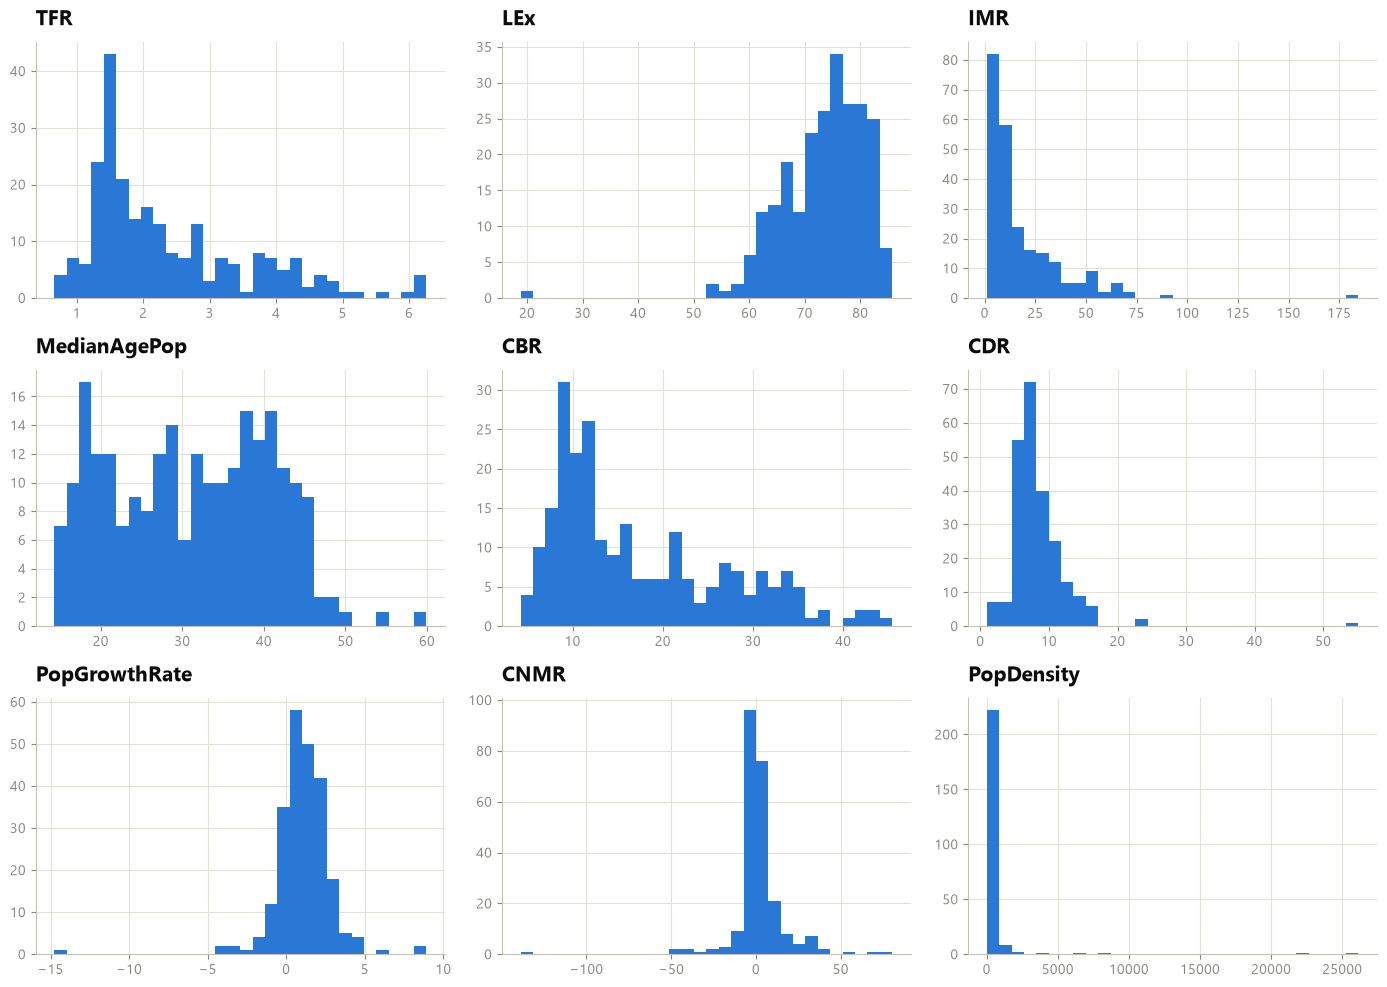

In [26]:
# Distribución de los indicadores principales en un año de PISA (2022)
principales = [
    "TFR",
    "LEx",
    "IMR",
    "MedianAgePop",
    "CBR",
    "CDR",
    "PopGrowthRate",
    "CNMR",
    "PopDensity",
]
anio = paises.loc[paises["Time"] == 2022]
anio[principales].hist(bins=30, figsize=(14, 10))
plt.tight_layout()

In [27]:
# Valores extremos en las estimaciones: ¿errores o casos reales?
for col in ["PopDensity", "CNMR", "PopSexRatio", "IMR", "SRB"]:
    print(f"--- {col}")
    display(estimados.nlargest(5, col)[["Location", "Time", col]])

--- PopDensity


,Location,Time,PopDensity
70449,Monaco,2023,26145.3020
70448,Monaco,2022,26128.5235
70447,Monaco,2021,25857.0470
70444,Monaco,2018,25607.0470
70445,Monaco,2019,25576.5101


--- CNMR


,Location,Time,CNMR
55190,"China, Hong Kong SAR",1964,357.140
55342,"China, Macao SAR",1964,354.537
60993,Kuwait,1991,340.853
61464,Qatar,2006,209.940
46254,Rwanda,1996,203.868


--- PopSexRatio


,Location,Time,PopSexRatio
61466,Qatar,2008,319.8502
61467,Qatar,2009,317.7096
61468,Qatar,2010,307.4882
61474,Qatar,2016,306.1817
61473,Qatar,2015,304.4668


--- IMR


,Location,Time,IMR
46702,South Sudan,1988,423.8092
62320,Yemen,1950,343.3954
62321,Yemen,1951,339.3315
62322,Yemen,1952,335.3810
62323,Yemen,1953,331.2165


--- SRB


,Location,Time,SRB
70137,Liechtenstein,2015,128.2
70136,Liechtenstein,2014,127.8
70138,Liechtenstein,2016,127.6
70135,Liechtenstein,2013,126.6
70139,Liechtenstein,2017,125.9


In [28]:
# Indicadores en los que hay valores negativos (estimaciones)
(estimados[indicadores] < 0).sum()[lambda s: s > 0]

NatChange        1009
NatChangeRT      1016
PopChange        1825
PopGrowthRate    1823
NetMigrations    9654
CNMR             9654
dtype: int64

## 6. Evolución temporal

Línea vertical: último año estimado (2023). Lo que está a la derecha son proyecciones, no datos observados.

Aun a la izquierda, no todo es observación directa: en países sin registro civil completo, la ONU estima con censos espaciados, encuestas y modelos indirectos, así que las series históricas de esos países son más inciertas (y más suaves) de lo que parecen.

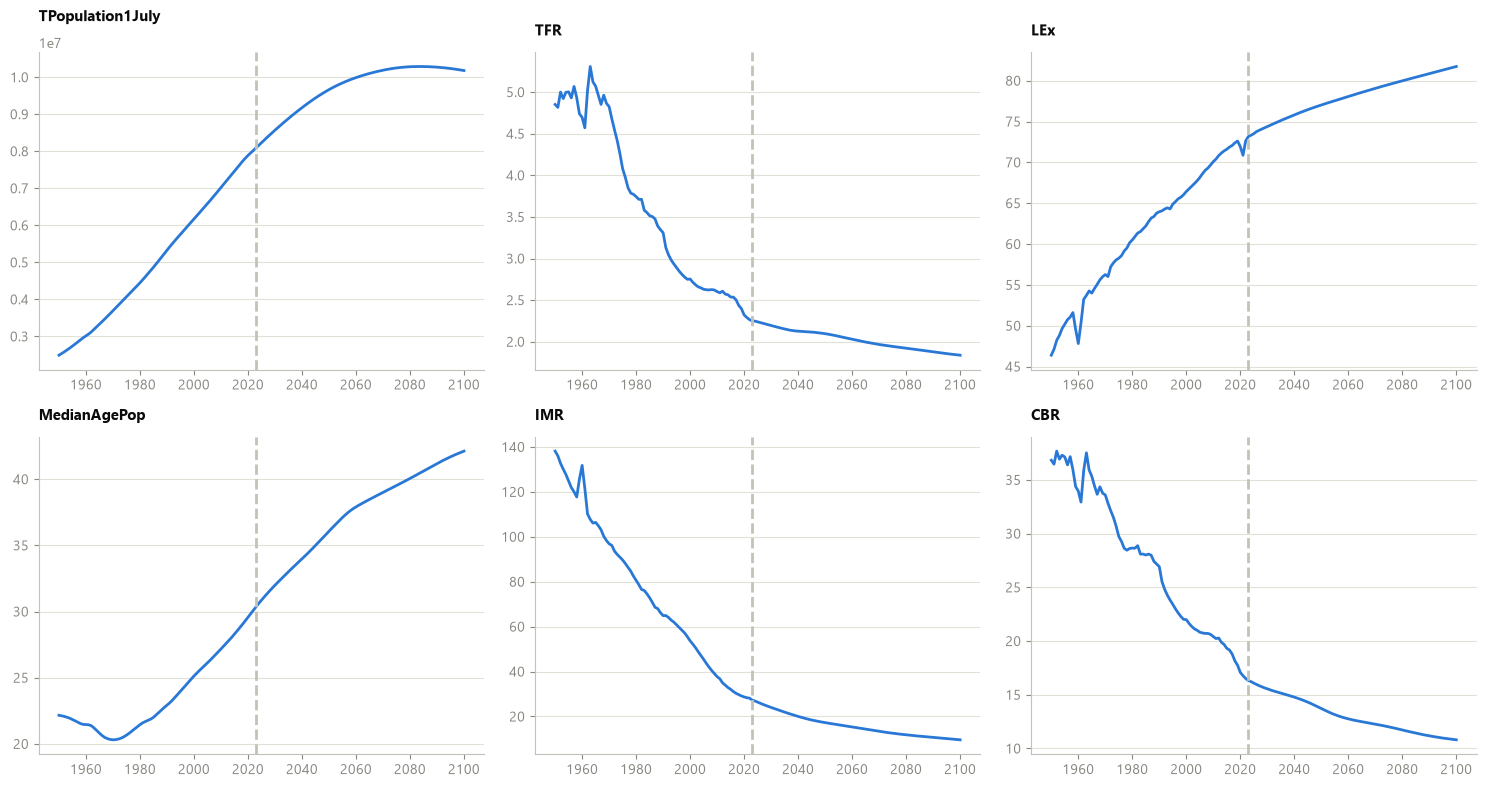

In [29]:
mundo = dem.loc[dem["LocTypeName"] == "World"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(
    axes.flat, ["TPopulation1July", "TFR", "LEx", "MedianAgePop", "IMR", "CBR"]
):
    ax.plot(mundo["Time"], mundo[col])
    ax.axvline(ULTIMO_ESTIMADO, color=GRIS, ls="--")
    ax.set_title(col, fontsize=11)
plt.tight_layout()

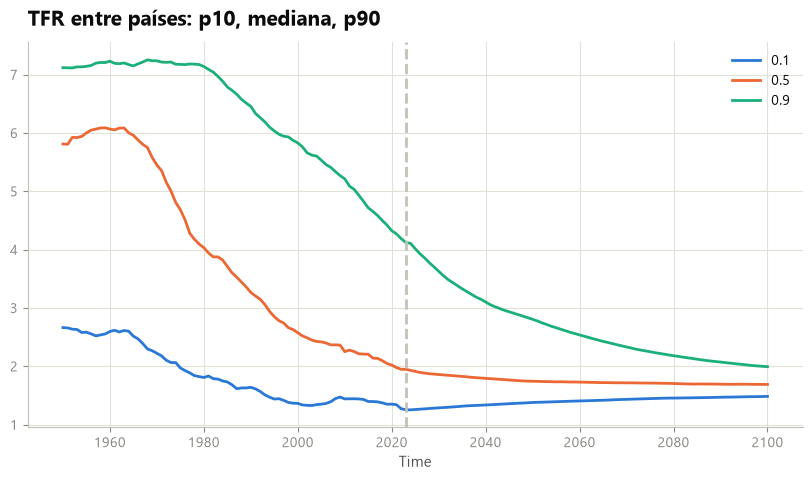

In [30]:
# Dispersión entre países a lo largo del tiempo (percentiles 10, 50 y 90 de la fecundidad)
q = paises.groupby("Time")["TFR"].quantile([0.1, 0.5, 0.9]).unstack()
ax = q.plot(figsize=(10, 5), title="TFR entre países: p10, mediana, p90")
ax.axvline(ULTIMO_ESTIMADO, color=GRIS, ls="--")

In [31]:
# Saltos bruscos de un año al siguiente (shocks: guerras, hambrunas, epidemias, COVID...)
salto = paises.groupby("ISO3_code")["LEx"].diff().abs()
paises.assign(salto_LEx=salto).nlargest(10, "salto_LEx")[
    ["Location", "Time", "LEx", "salto_LEx", "es_proyeccion"]
]

,Location,Time,LEx,salto_LEx,es_proyeccion
47953,Central African Republic,2023,57.4077,38.5900,False
47939,Central African Republic,2009,14.6655,35.2073,False
47940,Central African Republic,2010,46.8707,32.2052,False
46252,Rwanda,1994,12.1575,30.7796,False
58093,Cambodia,1979,41.0717,29.4991,False
46253,Rwanda,1995,41.5183,29.3608,False
58089,Cambodia,1975,12.7845,26.5113,False
46555,Somalia,1993,50.5506,25.5164,False
46713,South Sudan,1999,44.5371,25.4892,False
61131,Lebanon,1977,60.3312,23.8954,False


## 7. Supplement: coherencia con el Medium

El Supplement debería ser un complemento del Medium (mismos países y años). Compruebo cobertura, que los nacimientos por sexo sumen el total y que la razón de sexo al nacer implícita cuadre con `SRB`.

In [32]:
print("Años Supplement:", sup["Time"].min(), "-", sup["Time"].max())
print("Países solo en el Medium:", set(paises["ISO3_code"]) - set(sup["ISO3_code"]))
print("Países solo en el Supplement:", set(sup["ISO3_code"]) - set(paises["ISO3_code"]))

Años Supplement: 1950 - 2100
Países solo en el Medium: {'VAT'}
Países solo en el Supplement: set()


In [33]:
cruce = paises.merge(
    sup, on=["ISO3_code", "Time"], suffixes=("", "_sup"), validate="one_to_one"
)
print("Filas unidas:", len(cruce))
print("LocID distinto:", (cruce["LocID"] != cruce["LocID_sup"]).sum())
print("Nombre distinto:", (cruce["Location"] != cruce["Location_sup"]).sum())

dif_births = (cruce["BirthsMale"] + cruce["BirthsFemale"] - cruce["Births"]).abs()
print("Máx. |BirthsMale + BirthsFemale - Births| (miles):", dif_births.max().round(4))

srb_impl = 100 * cruce["BirthsMale"] / cruce["BirthsFemale"]
dif_srb = (srb_impl - cruce["SRB"]).abs()
print("Máx. |SRB implícita - SRB|:", dif_srb.max().round(2))
# Las diferencias grandes vienen del redondeo a miles en territorios con muy pocos nacimientos
print(
    "Filas con diferencia > 1:",
    (dif_srb > 1).sum(),
    "| máx. de Births en esas filas (miles):",
    cruce.loc[dif_srb > 1, "Births"].max(),
)

Filas unidas: 35636
LocID distinto: 0
Nombre distinto: 0
Máx. |BirthsMale + BirthsFemale - Births| (miles): 0.001
Máx. |SRB implícita - SRB|: 11.27
Filas con diferencia > 1: 660 | máx. de Births en esas filas (miles): 0.201


Filas con LE60 <= LE65: 0


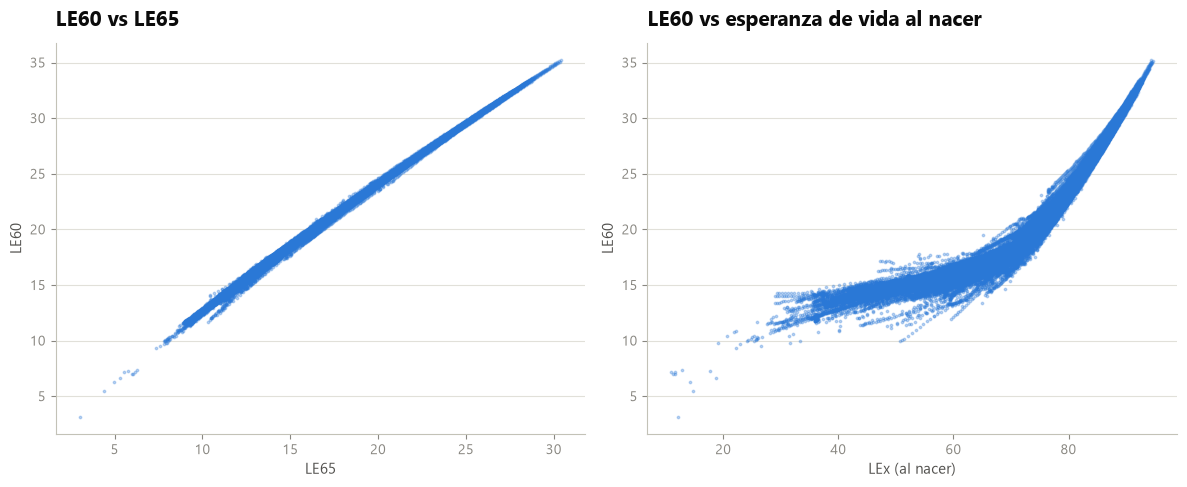

In [34]:
# LE60 debería estar entre LE65 y LE15 - 45
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(cruce["LE65"], cruce["LE60"], s=3, alpha=0.3)
axes[0].set(xlabel="LE65", ylabel="LE60", title="LE60 vs LE65")
axes[1].scatter(cruce["LEx"], cruce["LE60"], s=3, alpha=0.3)
axes[1].set(
    xlabel="LEx (al nacer)", ylabel="LE60", title="LE60 vs esperanza de vida al nacer"
)
plt.tight_layout()

print("Filas con LE60 <= LE65:", (cruce["LE60"] <= cruce["LE65"]).sum())

Filas con LE60 de hombres > mujeres: 107


<Axes: title={'left': 'Mediana entre países: LE60 mujeres - hombres (años)'}, xlabel='Time'>

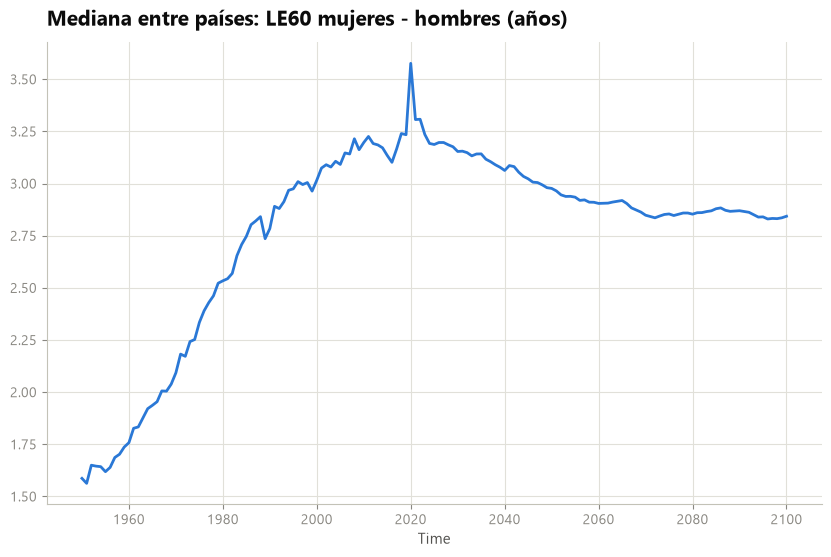

In [35]:
# Brecha por sexo en la esperanza de vida a los 60
brecha = sup.assign(brecha_LE60=sup["LE60Female"] - sup["LE60Male"])
print("Filas con LE60 de hombres > mujeres:", (brecha["brecha_LE60"] < 0).sum())
brecha.groupby("Time")["brecha_LE60"].median().plot(
    title="Mediana entre países: LE60 mujeres - hombres (años)"
)

## 8. Relaciones entre variables

Uso 2022 porque es el último ciclo de PISA con datos estimados (no proyectados), y 1970 solo como referencia histórica. Las correlaciones son descriptivas: no implican causalidad y esconden determinantes comunes (ingreso, educación, acceso a salud).

<Axes: >

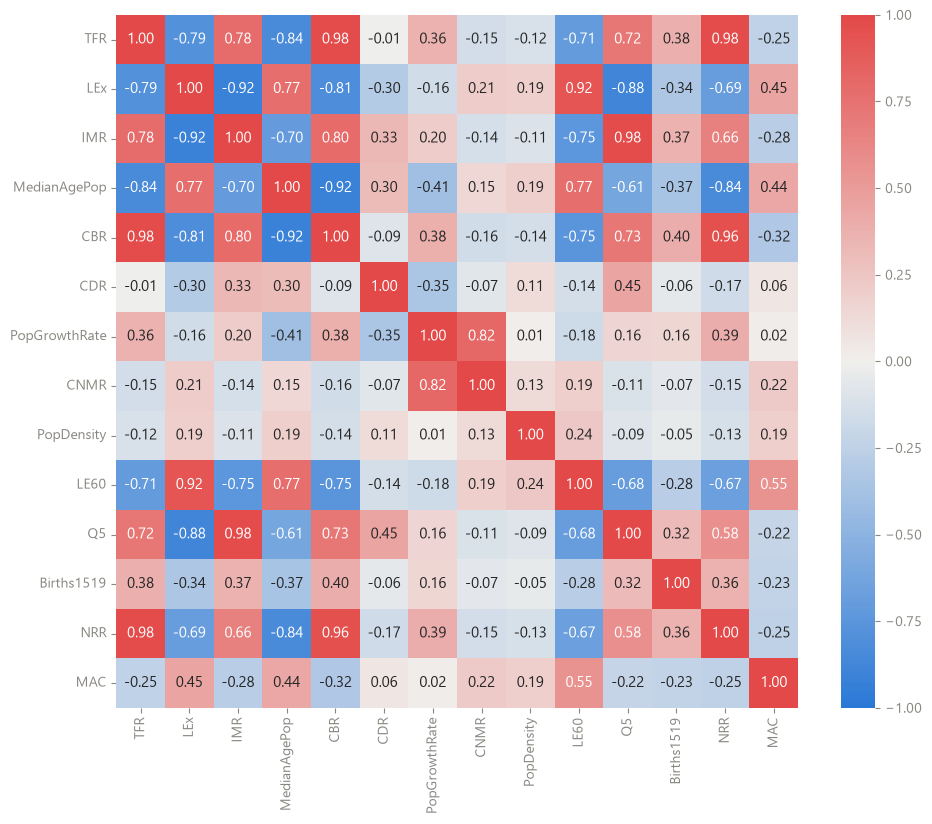

In [36]:
# Correlaciones entre indicadores principales (2022, solo países)
vars_corr = principales + ["LE60", "Q5", "Births1519", "NRR", "MAC"]
corr = cruce.loc[cruce["Time"] == 2022, vars_corr].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1, ax=ax)

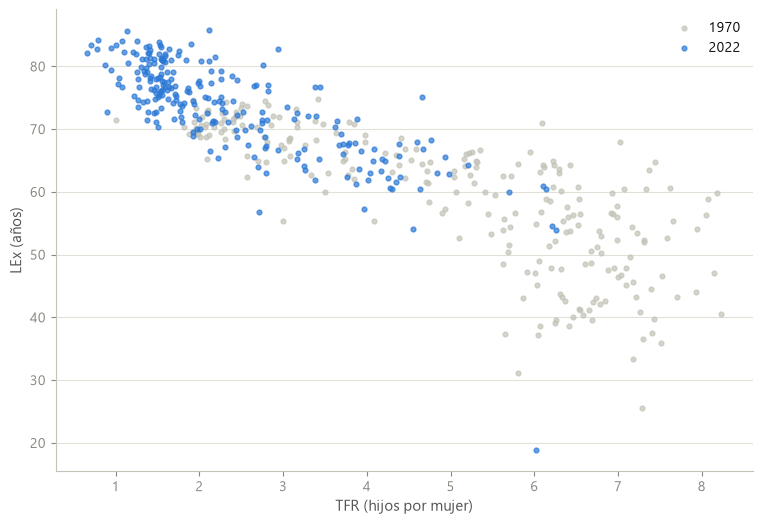

In [37]:
# Fecundidad vs esperanza de vida, 1970 vs 2022
fig, ax = plt.subplots(figsize=(9, 6))
for anio_, color in [(1970, GRIS), (2022, DESTACADO)]:
    d = paises.loc[paises["Time"] == anio_]
    ax.scatter(d["TFR"], d["LEx"], s=12, alpha=0.7, color=color, label=anio_)
ax.set(xlabel="TFR (hijos por mujer)", ylabel="LEx (años)")
ax.legend()

In [38]:
# Muchos indicadores son casi redundantes: ¿cuáles están correlacionados por encima de 0.95?
todos = cruce.loc[cruce["Time"] == 2022, indicadores + ["LE60"]].corr().abs()
pares = todos.where(lambda m: m.gt(0.95)).stack()
pares[[a < b for a, b in pares.index]].sort_values(ascending=False).head(30)

TPopulation1Jan         TPopulation1July          0.999994
Births                  LBsurvivingAge1           0.999920
TPopulation1July        TPopulationMale1July      0.999915
TPopulation1Jan         TPopulationFemale1July    0.999914
TPopulation1July        TPopulationFemale1July    0.999907
TPopulation1Jan         TPopulationMale1July      0.999898
TPopulationFemale1July  TPopulationMale1July      0.999645
Deaths                  DeathsMale                0.999358
                        DeathsFemale              0.999011
LE60                    LE65                      0.997394
DeathsFemale            DeathsMale                0.996776
Q0040                   Q0040Male                 0.996498
InfantDeaths            Under5Deaths              0.994079
LEx                     LExMale                   0.992681
Q1550                   Q1550Male                 0.992269
LEx                     LExFemale                 0.992222
Q0060Female             Q1560Female               0.9921

## 9. Otras variantes de proyección (`OtherVariants`)

Mismas columnas que el Medium, pero solo para los años de proyección (2024 en adelante) y con otros supuestos. Hay dos familias:

- **Escenarios deterministas:** cambian un supuesto y mantienen el resto como en el Medium. Por ejemplo, `High`/`Low` (fecundidad ±0,5 hijos), `Constant fertility`, `Zero migration`, `Constant mortality`, `Momentum`, `No change`...
- **Proyección probabilística:** `Median PI` y los intervalos de predicción del 80 % y 95 % (`Lower/Upper 80 PI`, `Lower/Upper 95 PI`), más `Mean`. Sirven para medir la **incertidumbre** de la proyección.

In [39]:
var = cargar_raw(
    "WPP2024_Demographic_Indicators_OtherVariants_csv.gz",
    compression="gzip",
    encoding="utf-8-sig",
    low_memory=False,
)
print("OtherVariants:", var.shape)
print("Mismas columnas que el Medium:", list(var.columns) == list(dem.columns))
var.head()

OtherVariants: (662919, 67)
Mismas columnas que el Medium: True


,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,3,High,2024,390004.975,393620.616,198181.186,195439.430,71.1699,101.4029,21.5046,8711.246,22.131,7231.281,1.837,37.7326,11231.922,820.222,28.535,3.7256,1.6977,28.679,105.8,2520.676,1394.924,1125.752,6.404,68.9901,66.3263,71.7537,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.4500,NaN,NaN,49.0291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1480.000,-3.760
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,3,High,2025,397236.256,400900.016,201757.834,199142.182,72.4861,101.3135,21.5772,8678.619,21.648,7327.520,1.828,37.9183,11241.189,825.791,28.040,3.6797,1.6793,28.697,105.8,2562.570,1417.698,1144.872,6.392,69.1359,66.4585,71.9100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.6442,NaN,NaN,48.0522,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1351.082,-3.370
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,3,High,2026,404563.776,408270.789,205385.771,202885.018,73.8188,101.2326,21.6545,8656.429,21.203,7414.026,1.816,38.1689,11259.609,834.970,27.579,3.6336,1.6606,28.716,105.8,2603.180,1439.265,1163.915,6.376,69.2752,66.5886,72.0549,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.9087,NaN,NaN,47.1683,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1242.396,-3.043
3,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,3,High,2027,411977.802,415756.788,209077.196,206679.592,75.1723,101.1601,21.7358,8655.022,20.817,7557.972,1.818,38.1269,11299.963,844.538,27.179,3.5907,1.6436,28.736,105.8,2644.941,1461.596,1183.345,6.362,69.4200,66.7235,72.2065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.0942,NaN,NaN,46.1997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1097.023,-2.639
4,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,3,High,2028,419535.774,423375.691,212840.890,210534.801,76.5499,101.0953,21.8254,8677.659,20.496,7679.834,1.814,38.2110,11365.130,850.528,26.844,3.5509,1.6277,28.755,105.7,2687.471,1484.745,1202.726,6.348,69.5740,66.8664,72.3698,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.2648,NaN,NaN,45.2131,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-997.864,-2.357


In [40]:
# Variantes: años, filas y nº de ubicaciones de cada una
var.groupby(["VarID", "Variant"]).agg(
    filas=("Time", "size"),
    desde=("Time", "min"),
    hasta=("Time", "max"),
    ubicaciones=("LocID", "nunique"),
)

,,filas,desde,hasta,ubicaciones
VarID,Variant,,,,
3,High,43290,2024,2101,555
4,Low,43290,2024,2101,555
5,Constant fertility,43290,2024,2101,555
6,Instant replacement,43290,2024,2101,555
7,Zero migration,43290,2024,2101,555
8,Constant mortality,43290,2024,2101,555
9,No change,43290,2024,2101,555
10,Momentum,43290,2024,2101,555
16,Instant replacement zero migration,43290,2024,2101,555


In [41]:
var_paises = var.loc[
    (var["LocTypeName"] == "Country/Area") & (var["Time"] < 2101)
].copy()
print(
    "Países por variante:",
    var_paises.groupby("Variant")["ISO3_code"].nunique().unique(),
)
print(
    "Duplicados (ISO3, variante, año):",
    var_paises.duplicated(["ISO3_code", "Variant", "Time"]).sum(),
)
print("Filas duplicadas:", var.duplicated().sum())

Países por variante: [237]
Duplicados (ISO3, variante, año): 0
Filas duplicadas: 0


Text(0.0, 1.0, 'Proporción de valores no nulos por variante e indicador (países, 2024-2100)')

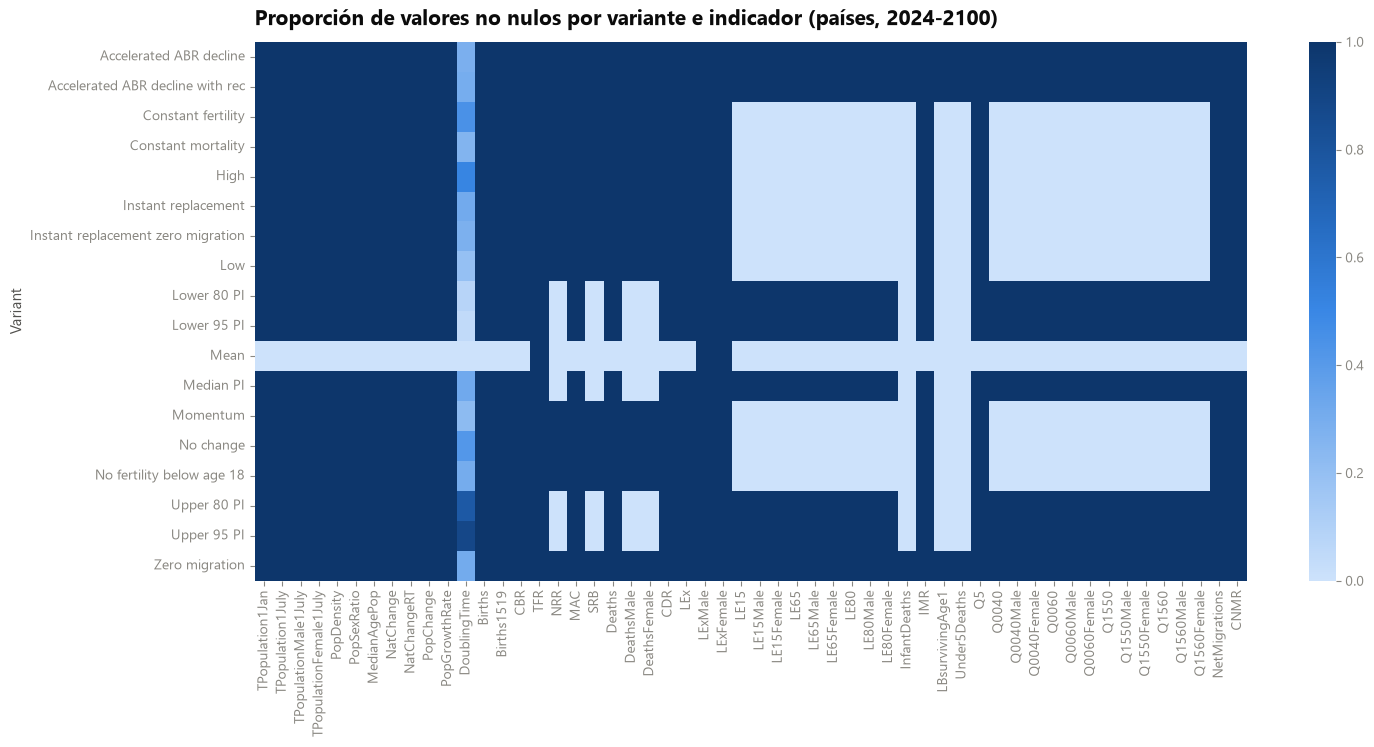

In [42]:
# Cobertura: qué indicadores trae cada variante (proporción de valores no nulos)
cobertura = var_paises.groupby("Variant")[indicadores].apply(lambda d: d.notna().mean())
fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(cobertura, cmap=CMAP_SECUENCIAL, vmin=0, vmax=1, ax=ax)
ax.set_title(
    "Proporción de valores no nulos por variante e indicador (países, 2024-2100)"
)

In [43]:
# Columnas que trae la variante Mean
cobertura.loc["Mean"][lambda s: s > 0]

TFR          1.0
LExMale      1.0
LExFemale    1.0
Name: Mean, dtype: float64

In [44]:
# Comparación con el Medium en los mismos países y años
clave = ["ISO3_code", "Time"]
for v in ["High", "Low", "Median PI", "Constant fertility", "Zero migration"]:
    j = var_paises.loc[var_paises["Variant"] == v].merge(
        paises[clave + ["TFR", "TPopulation1July"]], on=clave, suffixes=("", "_med")
    )
    d_tfr = j["TFR"] - j["TFR_med"]
    d_pop = (j["TPopulation1July"] / j["TPopulation1July_med"] - 1) * 100
    print(
        f"{v:20s} TFR - Medium: [{d_tfr.min():+.2f}, {d_tfr.max():+.2f}]  |  "
        f"población 2100 vs Medium (mediana): {d_pop[j['Time'] == 2100].median():+.1f} %"
    )

High                 TFR - Medium: [+0.25, +0.50]  |  población 2100 vs Medium (mediana): +42.7 %
Low                  TFR - Medium: [-0.50, -0.25]  |  población 2100 vs Medium (mediana): -32.2 %
Median PI            TFR - Medium: [-0.35, +0.04]  |  población 2100 vs Medium (mediana): +0.0 %
Constant fertility   TFR - Medium: [-0.58, +4.05]  |  población 2100 vs Medium (mediana): +14.8 %
Zero migration       TFR - Medium: [+0.00, +0.00]  |  población 2100 vs Medium (mediana): +4.3 %


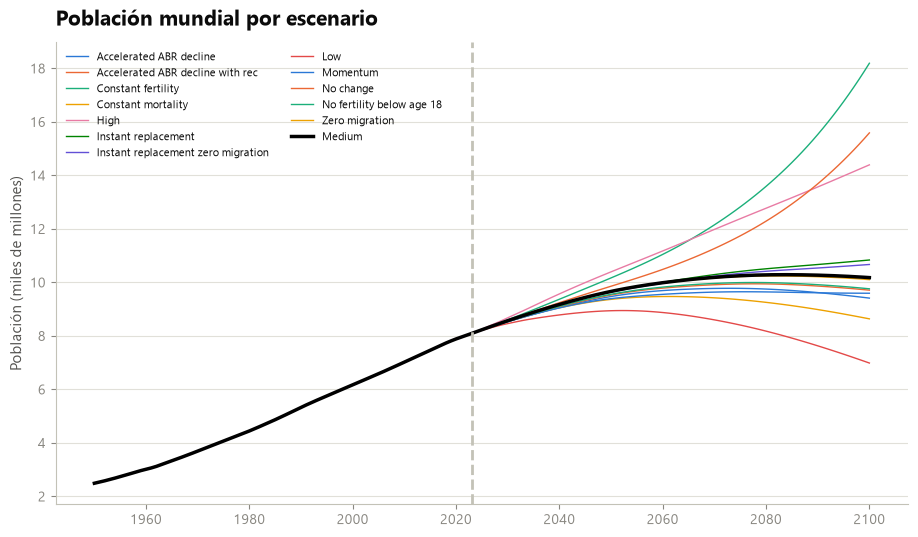

In [45]:
# Población mundial según cada escenario
var_mundo = var.loc[var["LocTypeName"] == "World"]
fig, ax = plt.subplots(figsize=(11, 6))
for v, d in var_mundo.loc[var_mundo["VarID"] < 200].groupby("Variant"):
    ax.plot(d["Time"], d["TPopulation1July"] / 1e6, lw=1, label=v)
med = mundo.loc[mundo["Time"].between(1950, 2100)]
ax.plot(
    med["Time"], med["TPopulation1July"] / 1e6, color="black", lw=2.5, label="Medium"
)
ax.axvline(ULTIMO_ESTIMADO, color=GRIS, ls="--")
ax.set(ylabel="Población (miles de millones)", title="Población mundial por escenario")
ax.legend(fontsize=8, ncol=2)

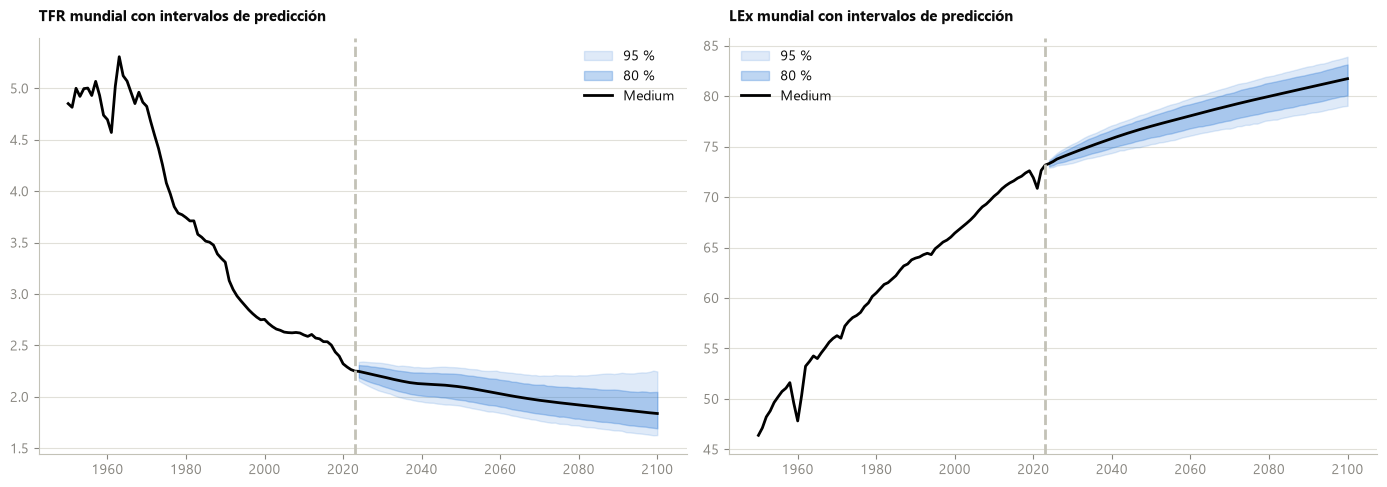

In [46]:
# Intervalos de predicción: TFR y esperanza de vida del mundo
pi = var_mundo.pivot_table(index="Time", columns="Variant", values=["TFR", "LEx"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["TFR", "LEx"]):
    ax.fill_between(
        pi.index,
        pi[(col, "Lower 95 PI")],
        pi[(col, "Upper 95 PI")],
        color=DESTACADO,
        alpha=0.15,
        label="95 %",
    )
    ax.fill_between(
        pi.index,
        pi[(col, "Lower 80 PI")],
        pi[(col, "Upper 80 PI")],
        color=DESTACADO,
        alpha=0.3,
        label="80 %",
    )
    ax.plot(mundo["Time"], mundo[col], color="black", label="Medium")
    ax.axvline(ULTIMO_ESTIMADO, color=GRIS, ls="--")
    ax.set_title(f"{col} mundial con intervalos de predicción", fontsize=11)
    ax.legend()
plt.tight_layout()

In [47]:
# Sensibilidad de una conclusión prospectiva: ¿en qué año alcanza su máximo la población mundial?
pico = (
    pd.concat([var_mundo, mundo.assign(Variant="Medium")])
    .loc[lambda d: d["Time"].between(2024, 2100) & d["Variant"].ne("Mean")]
    .sort_values("TPopulation1July")
    .groupby("Variant")
    .tail(1)
    .set_index("Variant")[["Time", "TPopulation1July"]]
    .rename(columns={"Time": "anio_pico", "TPopulation1July": "poblacion_pico_miles"})
)
pico["sigue_creciendo_en_2100"] = pico["anio_pico"].eq(2100)
pico.sort_values("anio_pico")

,anio_pico,poblacion_pico_miles,sigue_creciendo_en_2100
Variant,,,
Low,2052,8.948421e+06,False
Constant mortality,2061,9.474058e+06,False
Lower 95 PI,2068,9.658559e+06,False
Accelerated ABR decline,2073,9.780233e+06,False
Lower 80 PI,2075,9.818612e+06,False
Momentum,2076,9.650865e+06,False
Accelerated ABR decline with rec,2078,9.947883e+06,False
No fertility below age 18,2078,9.996417e+06,False
Zero migration,2082,1.024386e+07,False


In [48]:
# Coherencia: Lower 95 <= Lower 80 <= Median <= Upper 80 <= Upper 95
orden = ["Lower 95 PI", "Lower 80 PI", "Median PI", "Upper 80 PI", "Upper 95 PI"]
for col in ["TPopulation1July", "TFR", "LEx"]:
    t = var_paises.pivot_table(index=clave, columns="Variant", values=col)[orden]
    print(
        f"{col}: filas con intervalos desordenados =",
        (t.diff(axis=1).iloc[:, 1:] < 0).any(axis=1).sum(),
    )

# ¿Median PI coincide con el Medium?
j = var_paises.loc[var_paises["Variant"] == "Median PI"].merge(
    paises[clave + ["TPopulation1July"]], on=clave, suffixes=("", "_med")
)
print(
    "Máx. |Median PI - Medium| en población (miles):",
    (j["TPopulation1July"] - j["TPopulation1July_med"]).abs().max(),
)

TPopulation1July: filas con intervalos desordenados = 0
TFR: filas con intervalos desordenados = 0
LEx: filas con intervalos desordenados = 0
Máx. |Median PI - Medium| en población (miles): 0.0010000001639127731


In [49]:
# Incertidumbre en 2025 (año de PISA proyectado): ancho del intervalo del 95 % en los países de PISA
pisa_iso = cargar_processed("pisa_unificado.csv")["ISO3_code"].unique()
t = var_paises.loc[
    (var_paises["Time"] == 2025) & var_paises["ISO3_code"].isin(pisa_iso)
]
t = t.pivot_table(
    index="ISO3_code", columns="Variant", values=["TFR", "LEx", "TPopulation1July"]
)
ancho = pd.DataFrame(
    {
        "TFR (hijos)": t[("TFR", "Upper 95 PI")] - t[("TFR", "Lower 95 PI")],
        "LEx (años)": t[("LEx", "Upper 95 PI")] - t[("LEx", "Lower 95 PI")],
        "Población (% del Medium)": 100
        * (
            t[("TPopulation1July", "Upper 95 PI")]
            - t[("TPopulation1July", "Lower 95 PI")]
        )
        / t[("TPopulation1July", "Median PI")],
    }
)
ancho.describe().T

,count,mean,std,min,25%,50%,75%,max
TFR (hijos),100.0,0.639300,0.321485,0.345000,0.385250,0.533500,0.796750,2.062000
LEx (años),100.0,2.974200,0.490416,2.380000,2.570000,2.915000,3.240000,5.380000
Población (% del Medium),100.0,3.356838,5.577306,0.457533,1.020513,1.526468,2.328426,31.314984


## 10. Enlace con PISA

El objetivo es cruzar estos indicadores con `data/processed/pisa_unificado.csv` por `ISO3_code` y `Time`.

In [50]:
pisa = cargar_processed("pisa_unificado.csv")
print("Ciclos PISA:", sorted(pisa["Time"].unique()))
print("Países PISA:", pisa["ISO3_code"].nunique())
print(
    "Códigos de PISA que no están en WPP:",
    set(pisa["ISO3_code"]) - set(paises["ISO3_code"]),
)

Ciclos PISA: [np.int64(2000), np.int64(2003), np.int64(2006), np.int64(2009), np.int64(2012), np.int64(2015), np.int64(2018), np.int64(2022), np.int64(2025)]
Países PISA: 101
Códigos de PISA que no están en WPP: {'OED'}


In [51]:
# Cobertura: ¿cada fila de PISA encuentra su año en WPP?
enlace = pisa[["ISO3_code", "Time"]].merge(
    cruce[["ISO3_code", "Time", "TFR"]],
    on=["ISO3_code", "Time"],
    how="left",
    indicator=True,
)
enlace["_merge"].value_counts()

_merge
both          590
left_only       3
right_only      0
Name: count, dtype: int64

In [52]:
# Ojo: PISA 2025 cae en años de proyección de WPP
pisa["Time"].gt(2023).groupby(pisa["Time"]).sum()[lambda s: s > 0]

Time
2025    92
Name: Time, dtype: int64

## 11. Hallazgos → tareas para `02_limpieza`

- [ ] **Filtrar países:** quedarse con `LocTypeName == "Country/Area"` (237; equivale a `ISO3_code.notna()`). Sumar sin filtrar multiplica la población de 2023 por ~45. Si se usan agregados (Mundo, grupos de ingreso) como referencia, guardarlos aparte.
- [ ] **Quitar el año 2101:** solo trae `TPopulation1Jan`; el resto de columnas son nulas.
- [ ] **Separar estimación y proyección:** añadir una columna `es_proyeccion = Time > 2023`. PISA 2025 se cruzaría con datos proyectados.
- [ ] **Unir Medium + Supplement** por `ISO3_code` y `Time` (uno a uno, coinciden `LocID` y nombre). Vaticano (`VAT`) no está en el Supplement.
- [ ] **Descartar columnas sin uso:** `SortOrder`, `SDMX_code`, `LocTypeID`, `ParentID`, `VarID`, `Variant` (constantes o vacías en países). `BirthsMale + BirthsFemale` reproduce `Births`.
- [ ] **`DoublingTime`:** la ONU lo deja vacío cuando el crecimiento es ≤ 0,5 % anual (no solo cuando la población decrece). No imputar; probablemente no usarlo.
- [ ] **Territorios muy pequeños:** con < 200 nacimientos al año, el redondeo a miles distorsiona cocientes (p. ej. la SRB implícita del Supplement difiere hasta 11 puntos). Valorar un umbral de población mínima.
- [ ] **Unidades:** población, nacimientos, muertes y migrantes están en miles (×1.000 para cifras absolutas). `CBR`, `CDR`, `CNMR` son por 1.000 habitantes; `IMR` y `Q5` por 1.000 nacidos vivos; `TFR` en hijos por mujer. Documentar la unidad en cada eje y tabla.
- [ ] **Valores extremos reales, no errores:** densidades de microestados (Mónaco, Macao...), migración neta en países pequeños o en crisis, saltos de `LEx` por guerras o epidemias. Revisarlos al graficar, no eliminarlos.
- [ ] **Indicadores redundantes:** muchas variables están correlacionadas > 0.95 (versiones por sexo, LE15/LE60/LE65, CBR/TFR, IMR/Q5). Elegir pocas para el análisis.
- [ ] **LE60 por sexo:** en 107 filas los hombres superan a las mujeres; comprobar qué países y años antes de usar la brecha.
- [ ] **Enlace con PISA:** 590 de 593 filas de PISA encuentran su país-año en WPP. Las 3 que no son `OED` (promedio OCDE), que no existe en WPP: calcularlo como promedio de los países OCDE o excluirlo.
- [ ] **PISA 2025** (92 países) se cruza con proyecciones de WPP, no con estimaciones: marcarlo o avisarlo en el informe.
- [ ] **OtherVariants solo si hace falta:** son ~663 000 filas (18 variantes × 555 ubicaciones × 2024-2101). Para el análisis principal basta el Medium; usar `Lower/Upper 80/95 PI` solo para mostrar incertidumbre o escenarios (`High`/`Low`) como sensibilidad.
- [ ] **Cobertura desigual por variante:** las variantes probabilísticas (`PI`) no traen `NRR`, `SRB`, muertes por sexo ni muertes infantiles; varios escenarios deterministas no traen `LE15/65/80` ni las probabilidades `Q`. `Mean` solo trae `TFR`, `LExMale` y `LExFemale`. Comprobar la cobertura antes de elegir un indicador.
- [ ] **`Median PI` = Medium:** no aporta datos nuevos; descartarla.
- [ ] **Incertidumbre en PISA 2025:** el intervalo del 95 % de 2025 tiene una mediana de ±0,27 hijos en `TFR` y ±1,5 años en `LEx` en los países de PISA. Si se usan datos de 2025, mencionarlo.
- [ ] **Conclusiones prospectivas, siempre con su rango:** el año pico de la población mundial es 2084 en el Medium, pero va de 2068 (`Lower 95 PI`) a "sigue creciendo en 2100" (`Upper 80/95 PI`). Ningún resultado posterior a 2023 se presenta sin su intervalo o escenario alternativo.
- [ ] _..._

## 12. Criterios para `02_limpieza` y el informe (ASA)

- **Documentar el pipeline:** en `02_limpieza` dejar escritos los criterios de inclusión/exclusión de países (agregados, `OED`, territorios muy pequeños, Vaticano), el tratamiento de nulos (`DoublingTime`, 2101) y cuántas filas afecta cada decisión.
- **Decidir antes de mirar:** los años de análisis son los ciclos de PISA y la frontera es 2023. Si se cambia un criterio, se explica por qué, no porque "salga mejor".
- **Hechos vs. supuestos en el informe:** cada hallazgo indica si se basa en estimaciones (1950-2023) o en proyecciones (2024+), y en este caso con qué variante y qué incertidumbre.
- **Calidad desigual:** mencionar en *Limitaciones* que las estimaciones de países con registros civiles incompletos o en conflicto tienen más error, y que estos archivos no lo cuantifican por país.
- **Contexto y lenguaje:** al hablar de fecundidad, mortalidad infantil o migración, acompañar los datos de sus determinantes (ingreso, educación, conflictos, políticas) y evitar lecturas deterministas o que estigmaticen regiones o flujos migratorios.
- **Reproducibilidad:** cargar siempre desde `data/raw/` con `src/utils.py`; si en algún momento se simula o se muestrea, fijar la semilla.